Short note going through the high-gain analysis for the ideal waveguide configuration obtained in the other note. We use (z, $\omega$) equations of motion obtained from the generator of momentum.

In [1]:
# Go through imports and make sure everything is used

from scipy.linalg import expm
from custom_poling.core.custom_crystal import CustomCrystal
from NeedALight.spdc import JSA
from scipy.signal import peak_widths
from scipy.signal import find_peaks

from thewalrus.decompositions import blochmessiah

import numpy as np
import matplotlib.pyplot as plt

import snow.waveguides as waveguides
from scipy.constants import c
from tqdm import tqdm


# Defining constants for plotting purposes
nm = 1e-9
um = 1e-6
mm = 1e-3
fs = 1e-15
THz = 1e12

In [2]:
def prop_zw_single(w, ks, kp_w, gamma, z_list, domain, z0, Lambda_w):
    """Generates the Heisenberg propagator in (z,w) space using the equations of motion obtained from the Generator of Momentum
       for Type-0 degenerate operation

    Args:
        w (array): frequency values of interest for signal
        ks (array): signal dispersion relation
        kp_w (array): matrix  kp(w+w') needed in the exponential
        gamma (float): interaction strength parameter
        z_list (array): discretized interaction region
        domain (array): poling configuration
        z0 (float): initial position of pump, to properly compare with (k,t) method
        Lambda_w (function): Pump envelope function in frequency space

    Returns:
        K (array): Heisenberg Propagator in (z,w) space
    """
    dw = np.abs(w[1] - w[0])
    dz = z_list[1] - z_list[0]
    # Initializing
    K = np.identity(2 * len(w), dtype=np.complex128)

    # Constructing the diagonal blocks
    Rs = 0 * np.diag(1j * ks)
    Ri = 0 * np.diag(-1j * ks)

    # Note that for the pump, we explicitely remove the linear free-propagating phases here (For plotting purposes later)
    for i in range(len(z_list)):
        F = (
            1j
            * gamma
            * Lambda_w
            * np.exp(1j * (kp_w - ks - ks[:, np.newaxis]) * (z_list[i] - z0))
            * domain[i]
            * dw
        )
        Q = np.block([[Rs, F], [np.conjugate(F).T, Ri]])
        K = expm(Q * dz) @ K

    return K

## Preliminary definitions and waveguide setup. Generating the single-pass propagator and useful matrices/values.

We begin by generating the waveguide with ideal parameters

In [3]:
# Generating our waveguide
p_wl = 1045 * nm  # Pump wavelength
s_wl = 2 * p_wl  # Signal wavelength
hLN = 700 * nm
angle = 70

# Obtaining the poling for the ideal config
wg_test = waveguides.waveguide(
    w_top=942.274130 * nm,
    h_thinfilm=hLN,
    h_etch=hLN - 182.200000 * nm,
    theta=angle,
    tf_material="LN_MgO_e",
    clad_material="Air",
    box_material="SiO2",
)
# Obtaining poling period
n1 = wg_test.neff(p_wl)[0]
n2 = wg_test.neff(s_wl)[0]

Next, we define our pump parameters and obtain the dispersion relations in terms of frequency $\omega$. We also define the interaction strength, the spatial discretization, and a list of spatial values for the nonlinear crystal 

In [4]:
# Defining frequency range, pump envelope, and dispersion relations of signal and pump

# Length of the waveguide
L = 10 * mm

# Central frequncies
ws = 2 * np.pi * c / s_wl
wp = 2 * np.pi * c / p_wl

# Signal frequency span
wl_range = np.linspace(-0.3, 0.3, 801) * um  # wavelength range
wl = s_wl + wl_range[0]
wwmax = 2 * np.pi * c / wl
wwmin = 2 * ws - wwmax

Nw = 201
ww = np.linspace(wwmin, wwmax, Nw)

# Pump definitions here were to make sure they were properly L2 normalized
Ft = 50 * fs  # pulse-width: FWHM of intensity profile
Fl = (
    2 * np.log(2) * p_wl**2 / (np.pi * c * Ft)
)  # FWHM of intensity in terms of wavelength
sig_w = 2 * np.sqrt(np.log(2)) / Ft  # Standard deviation of pump amplitude
pump_w = lambda ww: np.exp(-((ww - wp) ** 2) / (2 * sig_w**2)) / np.power(
    np.pi * (sig_w) ** 2, 1 / 4
)


# Dispersion relations from SNOW
ksz = (
    wg_test.neff(2 * np.pi * c / ww) * (ww) / c
    - wg_test.neff(2 * np.pi * c / ws) * (ws) / c
)
wpz = (ww + ww[:, np.newaxis]).flatten()
kpzt = (
    wg_test.neff(2 * np.pi * c / wpz) * (wpz) / c
    - wg_test.neff(2 * np.pi * c / wp) * (wp) / c
)
kpz = kpzt.reshape(len(ww), len(ww))


# Interaction strength and spatial discretization
Np = 5.26e-10  # low-gain: 1.857e-14. Currently set to high-gain
gamma = np.sqrt(Np * c**3) / np.sqrt(
    2 * np.pi * 132565970**3
)  # the number denominator is the velocity of the modes

# Crystal properties
Ndomain = 1000  # Number of spatial points for non-linear/crystal grid
dz = (L) / Ndomain
domain_width = dz
number_domains = Ndomain
L22 = number_domains * domain_width

# Create a custom crystal object
custom_crystal_gauss = CustomCrystal(domain_width, number_domains)
domain_middles_gauss = custom_crystal_gauss.domain_middles

# Domain for a tophat potential
domain = np.asarray([1] * int(Ndomain) + [1])  #

# Spatial grid values for the non-linear region/crystal.
z_list = domain_middles_gauss - L / 2 - dz / 2

Next we generate the propagator for a single pass and obtain the relevant matrices and values from NeedALight.

In [5]:
U = prop_zw_single(
    ww, ksz, kpz, gamma, z_list, domain, 0, pump_w(ww + ww[:, np.newaxis])
)
# Generates JSA and other relevant matrices.
J, Ns, Schmidt, M, Nums, Numi = JSA(U, np.abs(ww[1] - ww[0]))

Here we plot the absolute value of the joint spectral amplitude (JSA) and output the average number of signal photons generated as well as the Schmidt number.

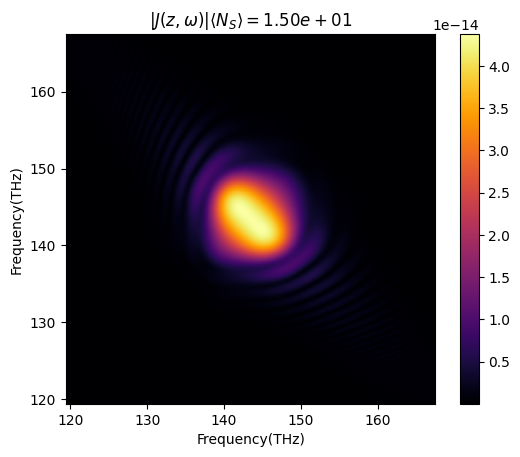

For 15.012163 average signal photons, we find a Schmidt number of 1.022479


In [6]:
# Generating plot for the abs(JSA) in terms of frequency(f)
fig, ax = plt.subplots()
im = ax.imshow(
    np.abs(J),
    cmap="inferno",
    origin="lower",
    extent=[
        ww[0] / (2 * np.pi * THz),
        ww[-1] / (2 * np.pi * THz),
        ww[0] / (2 * np.pi * THz),
        ww[-1] / (2 * np.pi * THz),
    ],
)
ax.set_xlabel("Frequency(THz)")
ax.set_ylabel("Frequency(THz)")
ax.set_title(r"$|J(z, \omega)|    \langle N_{S} \rangle = %1.2e $" % Ns)
plt.colorbar(im, orientation="vertical")
plt.show()

print("For %f average signal photons, we find a Schmidt number of %f" % (Ns, Schmidt))

## Mode distribution and temporal mode structure.

Next we look at the mode occupation fraction for the first five modes. The fraction we consider is $\frac{\sinh^2 r_{i}}{\sum_{k} \sinh^2 r_{k}}$. We also output the ratio of the first/second mode.

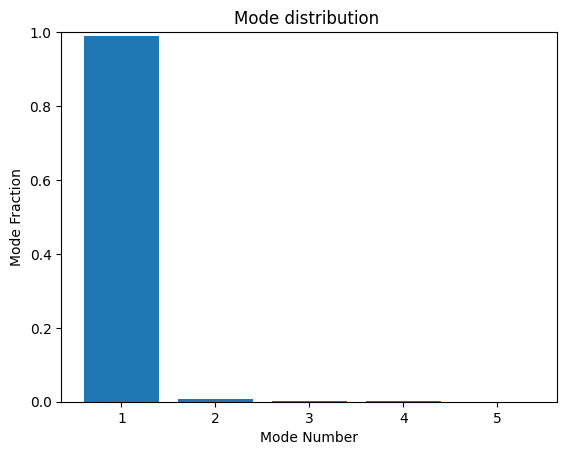

Ratio of first/second mode occupation is: 0.988920/0.006873


In [7]:
# Using SVD of M to construct JSA
L222, s, Vh = np.linalg.svd(M)
Sig = np.diag(s)
D = np.arcsinh(2 * Sig) / 2

D = np.diag(D)
Weight = np.sinh(D) ** 2

Normed = Weight[0:5] / np.sum(Weight)

fig, ax1 = plt.subplots()

ax1.bar(
    [1, 2, 3, 4, 5], Normed
)  # Here we multiply by a phase factor such that the imaginary part is 0 at the origin.
ax1.set_ylim([0, 1])
ax1.set_xlabel(r"Mode Number")
ax1.set_ylabel(r"Mode Fraction")
ax1.set_title(r"Mode distribution ")
plt.show()
print("Ratio of first/second mode occupation is: %f/%f" % (Normed[0], Normed[1]))

We now look at the temporal mode structure of the first mode, and obtain its bandwidth of operation (by considering the width of the intensity i.e. $|\psi(\omega)|^2$). We choose a gauge where the imaginary part of the mode is zero at the central frequency.

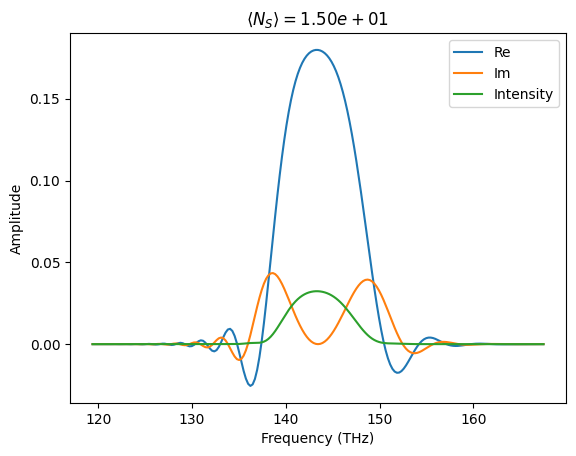

The operational bandwidth is 7.424188 THz


In [8]:
# Looking at the temporal modes via Nums matrix
mark = 1  # this just takes the first eigenmode of interest. Choose a different value to look at different ones.
val, u = np.linalg.eigh(Nums)

# This is to find the width of the intensity at half-max
diag = np.abs(u[:, -mark]) ** 2
peaks, _ = find_peaks(diag, height=0.025)
result_half = peak_widths(diag, peaks, rel_height=0.5)
results_half = peak_widths(diag, peaks, rel_height=0.5)

# Plotting the temporal mode in terms of frequency (f)
fig, ax1 = plt.subplots()
ax1.plot(
    ww / (2 * np.pi * THz),
    np.real(np.exp(-1j * np.angle(u[(Nw - 1) // 2, -mark])) * u[:, -mark]),
    label="Re",
)  # Here we multiply by a phase factor such that the imaginary part is 0 at the origin.
ax1.plot(
    ww / (2 * np.pi * THz),
    np.imag(np.exp(-1j * np.angle(u[(Nw - 1) // 2, -mark])) * u[:, -mark]),
    label="Im",
)
ax1.plot(ww / (2 * np.pi * THz), diag, label="Intensity")
ax1.set_xlabel("Frequency (THz)")
ax1.set_ylabel("Amplitude")
ax1.set_title(r"$\langle N_{S} \rangle= %1.2e$" % Ns)
ax1.legend()
plt.show()

print(
    "The operational bandwidth is %f THz"
    % (results_half[0][0] * (ww[1] - ww[0]) / (2 * np.pi * THz))
)

## Schmidt number and temporal mode overlap

Next we consider how the temporal mode structure and Schmidt number vary as a function of gain. We consider the overlap between a fixed low-gain temporal mode and a variable gain temporal mode as we increase gain. We also record the Schmidt number at different levels of gain.

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 21/21 [1:05:50<00:00, 188.14s/it]


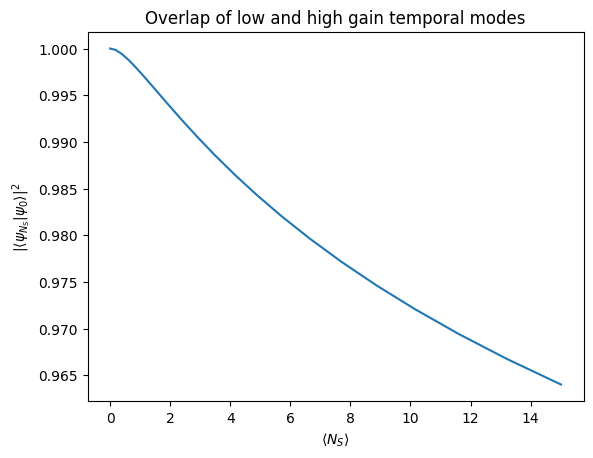

In [9]:
# Overlaps and Schmidt number as a function of Np
npi = 1e-15  # low-gain value
npf = 5.26e-10  # high-gain value
nstep = 21
num_pump = np.linspace(npi, npf, nstep)
nsv = np.zeros_like(num_pump)
K = np.zeros_like(num_pump)
Temp_mode = np.zeros([len(ww), len(num_pump)], dtype=np.complex128)
overlap = np.zeros(len(num_pump))


for i in tqdm(range(np.size(num_pump))):
    gamma = np.sqrt(num_pump[i] * c**3) / np.sqrt(2 * np.pi * 132565970**3)
    U = prop_zw_single(
        ww, ksz, kpz, gamma, z_list, domain, 0, pump_w(ww + ww[:, np.newaxis])
    )
    J2, Ns, Ks, M, Nums, Numi = JSA(U, np.abs(ww[1] - ww[0]))

    K[i] = Ks
    nsv[i] = Ns

    w, v = np.linalg.eigh(Nums)
    Temp_mode[:, i] = v[:, -1]
overlapmat = (
    np.abs(np.conj(Temp_mode).T @ Temp_mode) ** 2
)  # Matrix of all possible overlaps between states at different gains
overlap[:] = overlapmat[
    0, :
]  # Overlaps between fixed low level mode and all higher gain modes

# Plots the overlaps as a function of Ns
fig, ax = plt.subplots()
ax.plot(nsv, overlap)
ax.set_xlabel(r"$\langle N_{S} \rangle$")
ax.set_ylabel(r"$\left| \langle  \psi_{N_{S}}  | \psi_{0}   \rangle \right|^{2}$")
ax.set_title("Overlap of low and high gain temporal modes")travail ventilé et partiellement
fermé qui est conçu pour effectuer les tâc
plt.show()

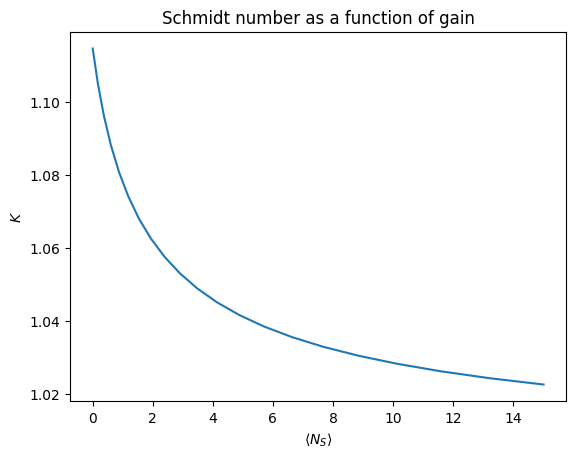

In [10]:
# Plotting the Schmidt number as a function of gain
fig, ax = plt.subplots()
ax.plot(nsv, K)
ax.set_xlabel(r"$\langle N_{S} \rangle$")
ax.set_ylabel(r"$K$")
ax.set_title("Schmidt number as a function of gain")
plt.show()

## All-optical measurement scheme. MOPA and SOPA overlaps.

Here we consider the all-optical measurment readout scheme. We consider a double-pass system where both passes are separated by 200 microns. We operate that 2nd pass as an anti-squeezer, as such the sign of the interaction stength is negative. We first obtain the input and output modes of the second pass for three different levels of gain, which correspond to 30, 40, and 50 dB of gain.

In [11]:
# Spatial grids for first and second pass of All-optical read out
z_list = domain_middles_gauss - L - dz / 2 - 100 * um
z_list2 = z_list + L + 200 * um

# For Blochmessiah decommp
mode_num = 0
R = (1 / np.sqrt(2)) * np.block(
    [
        [np.eye(len(U) // 2), 1j * np.eye(len(U) // 2)],
        [np.eye(len(U) // 2), -1j * np.eye(len(U) // 2)],
    ]
)


# Isolating the first output mode for different levels of gain for second pass
g30 = np.sqrt(1.26e-9 * c**3) / np.sqrt(2 * np.pi * 132565970**3)
U30 = prop_zw_single(
    ww, ksz, kpz, -g30, z_list2, domain, 0, pump_w(ww + ww[:, np.newaxis])
)
_J2, Ns30, _Schmidt30, _M2, Nums30, _Numi2 = JSA(U30, np.abs(ww[1] - ww[0]))
val, u = np.linalg.eigh(Nums30)
u30 = u[:, -1]
# To find the input mode we use Bloch-Messiah
S30 = np.real(np.conj(R).T @ U30 @ R)  # Converet to symplectic form
uff30, dff30, vff30 = blochmessiah(S30)
vff30 = vff30.T
# This is for the output mode, which is the same as the one obtained from the Ns matrix
real30 = np.real_if_close(uff30[0:Nw, mode_num])
imag30 = np.real_if_close(uff30[Nw : 2 * Nw, mode_num])
state30 = imag30 + 1j * real30
# This is for the input mode
real302 = np.real_if_close(vff30[0:Nw, mode_num])
imag302 = np.real_if_close(vff30[Nw : 2 * Nw, mode_num])
state302 = imag302 + 1j * real302


# The next two sets are for 40 and 50 dB of gain in the second pass
g40 = np.sqrt(2.04e-9 * c**3) / np.sqrt(2 * np.pi * 132565970**3)
U40 = prop_zw_single(
    ww, ksz, kpz, -g40, z_list2, domain, 0, pump_w(ww + ww[:, np.newaxis])
)
_J2, Ns40, _Schmidt30, _M2, Nums40, _Numi2 = JSA(U40, np.abs(ww[1] - ww[0]))
val, u = np.linalg.eigh(Nums40)
u40 = u[:, -1]
S40 = np.real(np.conj(R).T @ U40 @ R)
uff40, dff40, vff40 = blochmessiah(S40)
vff40 = vff40.T
real40 = np.real_if_close(uff40[0:Nw, mode_num])
imag40 = np.real_if_close(uff40[Nw : 2 * Nw, mode_num])
state40 = imag40 + 1j * real40
real402 = np.real_if_close(vff40[0:Nw, mode_num])
imag402 = np.real_if_close(vff40[Nw : 2 * Nw, mode_num])
state402 = imag402 + 1j * real402

g50 = np.sqrt(2.95e-9 * c**3) / np.sqrt(2 * np.pi * 132565970**3)  # 2.655
U50 = prop_zw_single(
    ww, ksz, kpz, -g50, z_list2, domain, 0, pump_w(ww + ww[:, np.newaxis])
)
_J2, Ns50, _Schmidt30, _M2, Nums50, _Numi2 = JSA(U50, np.abs(ww[1] - ww[0]))
val, u = np.linalg.eigh(Nums50)
u50 = u[:, -1]
S50 = np.real(np.conj(R).T @ U50 @ R)
uff50, dff50, vff50 = blochmessiah(S50)
vff50 = vff50.T
real50 = np.real_if_close(uff50[0:Nw, mode_num])
imag50 = np.real_if_close(uff50[Nw : 2 * Nw, mode_num])
state50 = imag50 + 1j * real50
real502 = np.real_if_close(vff50[0:Nw, mode_num])
imag502 = np.real_if_close(vff50[Nw : 2 * Nw, mode_num])
state502 = imag502 + 1j * real502

We now vary the amount of gain in the first pass from 15 to 23dB. Note that now we use gamma, and we have z_list rather than z_list2.

In [12]:
npi = 3.9e-10  # For 15 dB gain
npf = 8.1e-10  # For 23 dB gain
nstep = 5
num_pump = np.linspace(npi, npf, nstep)
nsv1 = np.zeros_like(num_pump)
f_oi = np.zeros([len(num_pump), 3])
f_oo = np.zeros([len(num_pump), 3])
f_oot = np.zeros([len(num_pump), 3])
f_o2ot = np.zeros([len(num_pump), 3])

for i in tqdm(range(np.size(num_pump))):
    gamma = np.sqrt(num_pump[i] * c**3) / np.sqrt(2 * np.pi * 132565970**3)
    U1 = prop_zw_single(
        ww, ksz, kpz, gamma, z_list, domain, 0, pump_w(ww + ww[:, np.newaxis])
    )
    _J2, Ns1, _Ks, _M, Nums1, _Numi = JSA(U1, np.abs(ww[1] - ww[0]))
    # Output mode for the first pass
    val, u = np.linalg.eigh(Nums1)
    u1 = u[:, -1]

    # Overlap between first output and second input
    f_oi[i, 0] = np.abs(np.vdot(u1, state302)) ** 2
    f_oi[i, 1] = np.abs(np.vdot(u1, state402)) ** 2
    f_oi[i, 2] = np.abs(np.vdot(u1, state502)) ** 2

    # Overlap between first output and second output
    f_oo[i, 0] = np.abs(np.vdot(u1, state30)) ** 2
    f_oo[i, 1] = np.abs(np.vdot(u1, state40)) ** 2
    f_oo[i, 2] = np.abs(np.vdot(u1, state50)) ** 2

    # Output mode for the total pass
    _J2, Nst30, _Ks, _M, Numst30, _Numi = JSA(U30 @ U1, np.abs(ww[1] - ww[0]))
    val, u3 = np.linalg.eigh(Numst30)
    u30t = u3[:, -1]
    f_oot[i, 0] = np.abs(np.vdot(u1, u30t)) ** 2
    f_o2ot[i, 0] = np.abs(np.vdot(state30, u30t)) ** 2

    _J2, Nst40, _Ks, _M, Numst40, _Numi = JSA(U40 @ U1, np.abs(ww[1] - ww[0]))
    val, u4 = np.linalg.eigh(Numst40)
    u40t = u4[:, -1]
    f_oot[i, 1] = np.abs(np.vdot(u1, u40t)) ** 2
    f_o2ot[i, 1] = np.abs(np.vdot(state40, u40t)) ** 2

    _J2, Nst50, _Ks, _M, Numst50, _Numi = JSA(U50 @ U1, np.abs(ww[1] - ww[0]))
    val, u5 = np.linalg.eigh(Numst50)
    u50t = u5[:, -1]
    f_oot[i, 2] = np.abs(np.vdot(u1, u50t)) ** 2
    f_o2ot[i, 2] = np.abs(np.vdot(state50, u50t)) ** 2

    nsv1[i] = Ns1

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [16:56<00:00, 203.32s/it]


Next we plot the overlap between the output modes of the MOPA and those of the Total system. Note that we have also generated a few different overlaps in the code which one can plot.

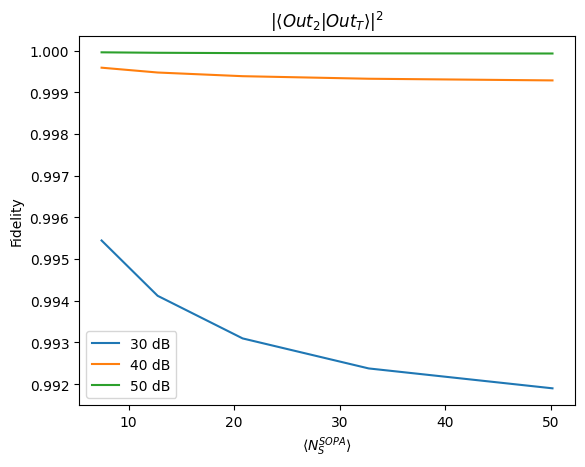

In [13]:
# Plots the overlaps as a function of Ns
fig, ax = plt.subplots()
ax.plot(nsv1, f_o2ot[:, 0], label=r"30 dB")
ax.plot(nsv1, f_o2ot[:, 1], label=r"40 dB")
ax.plot(nsv1, f_o2ot[:, 2], label=r"50 dB")
ax.set_xlabel(r"$\langle N^{SOPA}_{S} \rangle$")
ax.set_ylabel(r"Fidelity")
ax.set_title(r"$|\langle Out_{2}  |Out_{T}  \rangle|^{2}$")
plt.legend()
plt.show()